# 4 · Kamień, papier, nożyce z kwantowym botem

**Koło Naukowe Qubit, PWr** · kwantowa sieć, która uczy się Twoich nawyków (Qiskit + IQM)

Bot gra z Tobą w kamień, papier, nożyce. Jego „mózg” to obwód na **4 albo 5 kubitach**.
Po każdej rundzie bot stroi parametry obwodu, żeby lepiej przewidywać Twój następny ruch.
Na koniec gra na modelu Odry 5 **z szumem**.

Plan:
1. Dlaczego da się wygrać z człowiekiem, a z losowym graczem nie.
2. Obwód bota: jak go ułożyć, żeby pasował do gwiazdy Odry 5.
3. Uczenie: reguła przesunięcia parametru (parameter shift).
4. Turniej: bot 4- i 5-kubitowy, idealny i z szumem, kontra trzech symulowanych graczy.
5. Zagraj sam.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from iqm.qiskit_iqm import IQMFakeAdonis

adonis = IQMFakeAdonis()    # model 5-kubitowego komputera IQM z szumem (topologia gwiazdy jak Odra 5)
MOVES = ["kamień", "papier", "nożyce"]
ROCK, PAPER, SCISSORS = 0, 1, 2

def beats(move):
    # ruch, który bije podany: kamień -> papier, papier -> nożyce, nożyce -> kamień
    return (move + 1) % 3

## 1. Dlaczego bot może wygrać

Najlepsza strategia w tej grze to grać **całkiem losowo**: 1/3 kamień, 1/3 papier, 1/3 nożyce.
Wtedy nikt Cię nie ogra, ale Ty też nikogo nie ogrywasz: średnio 1/3 wygranych, 1/3 remisów, 1/3 przegranych.

Ludzie nie umieją grać losowo. Typowe nawyki:
- „gram po kolei”: kamień, papier, nożyce, kamień…
- „wygrałem, to zostaję; przegrałem, to zmieniam”,
- „trzy razy to samo? nie, to nie wygląda losowo”.

Bot szuka takich wzorców. Przewiduje Twój następny ruch i gra to, co go bije.

## 2. Mózg bota: obwód

| kubity | wersja 4-kubitowa | wersja 5-kubitowa |
|---|---|---|
| wejście | Twój ostatni ruch (2 kubity) | Twój ostatni ruch (2 kubity) + czy wygrałeś ostatnią rundę (1 kubit) |
| wyjście | przewidywany Twój ruch (2 kubity) | przewidywany Twój ruch (2 kubity) |

Wyjście czytamy tak: `o0 = 0, o1 = 0` to kamień, `o0 = 1` to papier, `o1 = 1` to nożyce.
Wynik `o0 = 1, o1 = 1` znaczy „nie wiem”: wtedy bot gra losowo.

**Topologia ma znaczenie.** Odra 5 to gwiazda: kubit centralny łączy się z czterema, a te nie łączą się ze sobą.
Dlatego `o0` siedzi w centrum, a obwód używa `CZ` tylko między centrum i resztą. Bez zamian kubitów (SWAP).

Dwie pułapki, na które wpadliśmy przy projektowaniu:
- Obwód „tablica w bramkach” (osobny obrót sterowany dla każdego wejścia) po kompilacji na Odrę 5 miał
  **261** bramek `CZ` na 4 kubitach i **917** na 5. Szum zrobiłby z niego czysty los.
- Warstwy „obróć wszystko, potem `CZ`” widziały tylko **parzystość** bitów wejścia, więc papier (`10`) i nożyce (`01`)
  wyglądały dla bota tak samo. Pomogło przeplatanie: obrót centrum, `CZ` z jednym kubitem, obrót centrum, `CZ` z następnym…

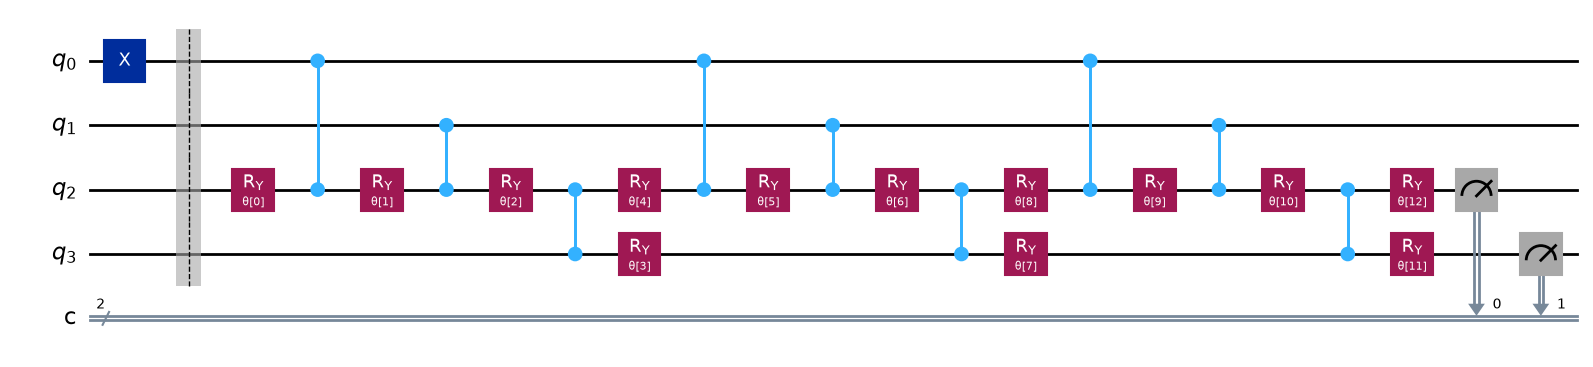

In [3]:
LAYERS = 3

def bot_gates(n_qubits):
    # Lista bramek: ("ry", kubit, nr parametru) albo ("cz", centrum, kubit).
    # Kubity: 0..n-3 wejście, n-2 = o0 (centrum gwiazdy), n-1 = o1.
    center = n_qubits - 2
    leaves = [q for q in range(n_qubits) if q != center]
    gates, k = [], 0
    for _ in range(LAYERS):
        for q in leaves:
            gates.append(("ry", center, k)); k += 1
            gates.append(("cz", center, q))
        gates.append(("ry", n_qubits - 1, k)); k += 1
    gates.append(("ry", center, k)); k += 1
    return gates, k

def bot_circuit(n_qubits, input_bits, measure=True):
    gates, n_params = bot_gates(n_qubits)
    theta = ParameterVector("θ", n_params)
    qc = QuantumCircuit(n_qubits, 2)
    for q, bit in enumerate(input_bits):
        if bit:
            qc.x(q)
    qc.barrier()
    for g in gates:
        if g[0] == "ry":
            qc.ry(theta[g[2]], g[1])
        else:
            qc.cz(g[1], g[2])
    if measure:
        qc.measure([n_qubits - 2, n_qubits - 1], [0, 1])
    return qc

def star_layout(n_qubits):
    # logiczny kubit o0 -> fizyczny kubit 2 (centrum gwiazdy w IQMFakeAdonis), reszta na ramiona
    layout = [0, 1, 3, 4][: n_qubits - 1]
    layout.insert(n_qubits - 2, 2)
    return layout

bot_circuit(4, [1, 0]).draw("mpl", fold=-1)

In [4]:
for n in (4, 5):
    tqc = transpile(bot_circuit(n, [0] * (n - 2)), adonis, initial_layout=star_layout(n), optimization_level=1)
    print(f"{n} kubitów: parametrów = {bot_gates(n)[1]}, bramek CZ po kompilacji = {tqc.count_ops()['cz']}, głębokość = {tqc.depth()}")

4 kubitów: parametrów = 13, bramek CZ po kompilacji = 9, głębokość = 20
5 kubitów: parametrów = 16, bramek CZ po kompilacji = 12, głębokość = 26


### Mini-symulator

Uczenie wymaga tysięcy przebiegów obwodu, więc liczymy go własnym symulatorem w `numpy`
(5 kubitów to tylko 32 amplitudy). Liczy wiele zestawów parametrów i wejść naraz.
Najpierw sprawdzamy, że daje to samo co Qiskit.

In [5]:
def simulate(n_qubits, gates, params, inputs):
    # params: (B, P), inputs: lista bitów wejścia -> prawdopodobieństwa (B, liczba wejść, 4)
    # indeks wyniku = o0 + 2 * o1  (0 kamień, 1 papier, 2 nożyce, 3 "nie wiem")
    B = params.shape[0]
    psi = np.zeros((B, len(inputs)) + (2,) * n_qubits)
    for i, bits in enumerate(inputs):
        psi[(slice(None), i) + tuple(bits) + (0, 0)] = 1
    grid = np.indices((2,) * n_qubits)
    shape = (B,) + (1,) * n_qubits
    for g in gates:
        if g[0] == "ry":
            q, t = g[1], params[:, g[2]]
            c, s = np.cos(t / 2).reshape(shape), np.sin(t / 2).reshape(shape)
            a, b = np.take(psi, 0, axis=2 + q), np.take(psi, 1, axis=2 + q)
            psi = np.stack([c * a - s * b, s * a + c * b], axis=2 + q)
        else:
            psi = psi * np.where((grid[g[1]] == 1) & (grid[g[2]] == 1), -1, 1)
    p = (psi ** 2).sum(axis=tuple(range(2, n_qubits)))      # zostają tylko o0, o1
    return p.transpose(0, 1, 3, 2).reshape(B, len(inputs), 4)

n, bits = 5, [0, 1, 1]
gates, n_params = bot_gates(n)
theta = np.random.default_rng(0).normal(size=n_params)
ours = simulate(n, gates, theta[None], [bits])[0, 0]
qc = bot_circuit(n, bits, measure=False).assign_parameters(theta)
theirs = Statevector(qc).probabilities([n - 2, n - 1])
print("mini-symulator:", np.round(ours, 4))
print("Qiskit:        ", np.round(theirs, 4))
assert np.allclose(ours, theirs)

mini-symulator: [0.0827 0.1453 0.5026 0.2694]
Qiskit:         [0.0827 0.1453 0.5026 0.2694]


## 3. Uczenie

Bot pamięta, co grałeś po każdym wejściu (starsze rundy powoli zapomina, żeby nadążyć, gdy zmienisz styl).
Cel: obwód ma dawać wysokie prawdopodobieństwo ruchom, które naprawdę grasz.

Do tego potrzebny jest gradient, czyli jak zmienić każdy kąt $\theta_k$. Na komputerze kwantowym liczy się go
**regułą przesunięcia parametru**: uruchamiamy obwód dwa razy, z kątem przesuniętym o $\pm\pi/2$:

$$\frac{\partial p}{\partial \theta_k} = \frac{p(\theta_k + \pi/2) - p(\theta_k - \pi/2)}{2}$$

To nie jest przybliżenie, tylko dokładny wzór dla bramek `RY`. Działa też na prawdziwym sprzęcie.
Parametry poprawia optymalizator Adam (ten sam, którym trenuje się zwykłe sieci neuronowe).

W każdej rundzie bot robi tak:
1. Wpisuje Twój ostatni ruch (i wynik) na kubity wejścia.
2. **Mierzy** wyjście raz. Wynik pomiaru to przewidywany Twój ruch, więc bot gra to, co go bije.
   Gdy bot nic nie wie, pomiar jest losowy, i to prawdziwie losowy.
3. Widzi Twój ruch i poprawia parametry.

In [6]:
class QuantumBot:
    def __init__(self, n_qubits, backend=None, seed=0, memory=0.97, steps=3, lr=0.1):
        self.n = n_qubits
        self.gates, self.n_params = bot_gates(n_qubits)
        self.backend = backend                     # None = idealny pomiar, inaczej np. adonis
        self.rng = np.random.default_rng(seed)
        self.theta = self.rng.normal(0, 0.3, self.n_params)
        self.adam_m = np.zeros(self.n_params)
        self.adam_v = np.zeros(self.n_params)
        self.t = 0
        self.memory, self.steps, self.lr = memory, steps, lr
        uses_result = n_qubits == 5
        self.inputs = [[m & 1, m >> 1] + ([w] if uses_result else [])
                       for m in range(3) for w in ((0, 1) if uses_result else (0,))]
        self.counts = np.zeros((len(self.inputs), 4))
        self.compiled = {}

    def context(self, last_move, you_won):
        return self.inputs.index([last_move & 1, last_move >> 1] + ([int(you_won)] if self.n == 5 else []))

    def probabilities(self, ctx):
        return simulate(self.n, self.gates, self.theta[None], [self.inputs[ctx]])[0, 0]

    def measure(self, ctx):
        if self.backend is None:
            p = self.probabilities(ctx)
            return int(self.rng.choice(4, p=p / p.sum()))
        if ctx not in self.compiled:
            qc = bot_circuit(self.n, self.inputs[ctx])
            self.compiled[ctx] = transpile(qc, self.backend, initial_layout=star_layout(self.n), optimization_level=1)
        qc = self.compiled[ctx].assign_parameters(self.theta)
        result = self.backend.run(qc, shots=1, seed_simulator=int(self.rng.integers(2**31))).result()
        bits = next(iter(result.get_counts()))   # napis "o1 o0"
        return int(bits[1]) + 2 * int(bits[0])

    def choose(self, ctx):
        guess = self.measure(ctx)
        move = beats(guess) if guess < 3 else int(self.rng.integers(3))
        return move, guess

    def learn(self, ctx, your_move):
        self.counts *= self.memory
        self.counts[ctx, your_move] += 1
        P, shift = self.n_params, np.eye(self.n_params) * np.pi / 2
        for _ in range(self.steps):
            batch = np.vstack([self.theta[None], self.theta + shift, self.theta - shift])
            p = simulate(self.n, self.gates, batch, self.inputs)
            p0 = np.maximum(p[0], 1e-6)
            dp = (p[1:P + 1] - p[P + 1:]) / 2                         # reguła przesunięcia parametru
            grad = -(self.counts * dp / p0).sum(axis=(1, 2)) / self.counts.sum()
            self.t += 1
            self.adam_m = 0.9 * self.adam_m + 0.1 * grad
            self.adam_v = 0.999 * self.adam_v + 0.001 * grad ** 2
            m_hat = self.adam_m / (1 - 0.9 ** self.t)
            v_hat = self.adam_v / (1 - 0.999 ** self.t)
            self.theta -= self.lr * m_hat / (np.sqrt(v_hat) + 1e-8)

## 4. Turniej

Trzech symulowanych graczy:
- **po kolei**: gra ruch po swoim ostatnim (kamień → papier → nożyce), w 80% rund; w pozostałych losowo.
- **zostań / zmień**: po wygranej powtarza ruch, po przegranej lub remisie przechodzi na następny, w 80% rund.
- **losowy**: zawsze losowo.

Gracz „zostań / zmień” to test dla piątego kubitu: bez informacji, czy gracz wygrał, nie da się go w pełni przewidzieć.

Bot z szumem gra na `IQMFakeAdonis`, jeden pomiar (shot) na rundę. To trwa ok. minuty.

In [7]:
def player_cycle(rng, last, won):
    return (last + 1) % 3 if rng.random() < 0.8 else int(rng.integers(3))

def player_win_stay(rng, last, won):
    if rng.random() >= 0.8:
        return int(rng.integers(3))
    return last if won else (last + 1) % 3

def player_random(rng, last, won):
    return int(rng.integers(3))

PLAYERS = {"po kolei": player_cycle, "zostań / zmień": player_win_stay, "losowy": player_random}

def play(bot, player, rounds=300, seed=1):
    # zwraca wynik każdej rundy z punktu widzenia bota: +1 wygrana, 0 remis, -1 przegrana
    rng = np.random.default_rng(seed)
    last, won = int(rng.integers(3)), False
    results = []
    for _ in range(rounds):
        ctx = bot.context(last, won)
        bot_move, _ = bot.choose(ctx)
        you = player(rng, last, won)
        r = 1 if bot_move == beats(you) else (-1 if you == beats(bot_move) else 0)
        results.append(r)
        bot.learn(ctx, you)
        last, won = you, r == -1
    return np.array(results)

BOTS = {
    "4 kubity, idealnie": lambda: QuantumBot(4),
    "4 kubity, Odra 5": lambda: QuantumBot(4, backend=adonis),
    "5 kubitów, idealnie": lambda: QuantumBot(5),
    "5 kubitów, Odra 5": lambda: QuantumBot(5, backend=adonis),
}
tournament = {(p, b): play(make(), PLAYERS[p]) for p in PLAYERS for b, make in BOTS.items()}

print(f"{'gracz':16}" + "".join(f"{b:>22}" for b in BOTS))
for p in PLAYERS:
    print(f"{p:16}" + "".join(f"{np.mean(tournament[p, b] == 1):>21.0%} " for b in BOTS))
print("\n(procent rund wygranych przez bota; czysty los daje ok. 33%)")

gracz               4 kubity, idealnie      4 kubity, Odra 5   5 kubitów, idealnie     5 kubitów, Odra 5
po kolei                          72%                   62%                   73%                   60% 
zostań / zmień                    52%                   40%                   70%                   54% 
losowy                            33%                   34%                   35%                   26% 

(procent rund wygranych przez bota; czysty los daje ok. 33%)


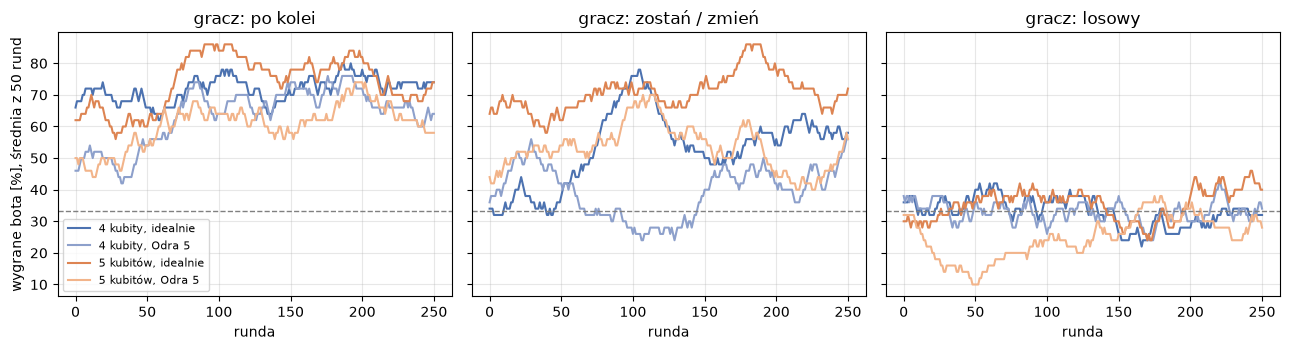

In [8]:
def rolling(x, w=50):
    return np.convolve(x, np.ones(w) / w, mode="valid")

colors = {"4 kubity, idealnie": "#4C72B0", "4 kubity, Odra 5": "#8DA0CB",
          "5 kubitów, idealnie": "#DD8452", "5 kubitów, Odra 5": "#F2B48A"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, p in zip(axes, PLAYERS):
    for b in BOTS:
        ax.plot(rolling(tournament[p, b] == 1) * 100, label=b, color=colors[b])
    ax.axhline(100 / 3, color="gray", ls="--", lw=1)
    ax.set_title(f"gracz: {p}"); ax.set_xlabel("runda"); ax.grid(alpha=0.3)
axes[0].set_ylabel("wygrane bota [%], średnia z 50 rund")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Co widać:**
- Gracza „po kolei” ogrywają oba boty: do odgadnięcia wystarczy ostatni ruch.
- Gracza „zostań / zmień” wyraźnie lepiej ogrywa bot 5-kubitowy. Piąty kubit (czy wygrałeś) niesie potrzebną informację.
- Szum Odry 5 zabiera botowi część przewagi: czasem pomiar daje inny ruch, niż obwód „chciał”.
- Gracza losowego nie ogra nikt. To nie wada bota, tylko matematyka.

> Uczciwie: zwykła tabelka „po kamieniu gracz zwykle gra papier” zrobi to samo bez kubitów.
> Tu obwód jest nośnikiem modelu i źródłem losowości, a nie przyspieszeniem. Za to cały schemat (obwód z parametrami,
> reguła przesunięcia parametru, optymalizator klasyczny) to dokładnie to, jak trenuje się kwantowe sieci na prawdziwym sprzęcie.

Co bot wie o graczu „zostań / zmień” po turnieju? Dla każdego wejścia: jak bardzo spodziewa się każdego ruchu.

In [9]:
bot = QuantumBot(5)
play(bot, player_win_stay)
for ctx, bits in enumerate(bot.inputs):
    last, won = bits[0] + 2 * bits[1], bits[2]
    p = bot.probabilities(ctx)
    guess = ", ".join(f"{MOVES[m]} {p[m]:.0%}" for m in range(3))
    print(f"ostatnio {MOVES[last]:7} {'wygrałeś' if won else 'nie wygrałeś':12} -> przewiduję: {guess}")

ostatnio kamień  nie wygrałeś -> przewiduję: kamień 12%, papier 82%, nożyce 6%
ostatnio kamień  wygrałeś     -> przewiduję: kamień 57%, papier 33%, nożyce 0%
ostatnio papier  nie wygrałeś -> przewiduję: kamień 1%, papier 12%, nożyce 86%
ostatnio papier  wygrałeś     -> przewiduję: kamień 2%, papier 95%, nożyce 2%
ostatnio nożyce  nie wygrałeś -> przewiduję: kamień 84%, papier 8%, nożyce 7%
ostatnio nożyce  wygrałeś     -> przewiduję: kamień 3%, papier 22%, nożyce 71%


## 5. Zagraj sam

Klikaj przyciski. Bot pokazuje, czego się po Tobie spodziewał. Spróbuj grać „losowo” przez 30 rund
i zobacz, czy bot coś wyłapie. Przełącznik zmienia bota na grę na modelu Odry 5 z szumem.

In [10]:
import ipywidgets as widgets

class Match:
    def __init__(self, noisy=False):
        self.bot = QuantumBot(5, backend=adonis if noisy else None, seed=None)
        self.last, self.won = int(np.random.default_rng().integers(3)), False
        self.score = {"bot": 0, "ty": 0, "remis": 0}

    def play(self, you):
        ctx = self.bot.context(self.last, self.won)
        expected = self.bot.probabilities(ctx)
        bot_move, _ = self.bot.choose(ctx)
        if bot_move == beats(you):
            outcome = "bot"
        elif you == beats(bot_move):
            outcome = "ty"
        else:
            outcome = "remis"
        self.score[outcome] += 1
        self.bot.learn(ctx, you)
        self.last, self.won = you, outcome == "ty"
        guess = ", ".join(f"{MOVES[m]} {expected[m]:.0%}" for m in range(3))
        return (f"Ty: {MOVES[you]}, bot: {MOVES[bot_move]} -> wygrywa: {outcome}\n"
                f"Bot spodziewał się: {guess}\n"
                f"Wynik: bot {self.score['bot']}, ty {self.score['ty']}, remisy {self.score['remis']}")

match = Match()
out = widgets.Output()
noisy = widgets.Checkbox(description="gra na modelu Odry 5 (szum)")

def on_move(button):
    with out:
        out.clear_output()
        print(match.play(MOVES.index(button.description)))

def on_noise(change):
    global match
    match = Match(noisy=change["new"])
    with out:
        out.clear_output()
        print("Nowy mecz.")

buttons = [widgets.Button(description=m) for m in MOVES]
for b in buttons:
    b.on_click(on_move)
noisy.observe(on_noise, names="value")
display(widgets.VBox([widgets.HBox(buttons), noisy, out]))

## 6. Wyzwania

1. **Dłuższa pamięć**: bot widzi tylko ostatnią rundę. Jak zmieścić dwie ostatnie rundy? Ile kubitów i bramek `CZ` to kosztuje?
2. **Trening z szumem**: teraz bot uczy się na idealnym symulatorze, a gra na Odrze 5. Czy bot uczony na pomiarach
   z szumem (reguła przesunięcia też działa na sprzęcie) gra lepiej?
3. **Bot kontra bot**: dwa kwantowe boty uczą się na sobie nawzajem. Czy dojdą do gry losowej (1/3, 1/3, 1/3)?
4. **Nagraj ludzi**: zbierzcie na spotkaniu 50 rund od kilku osób. Kogo bot ogrywa najmocniej?
5. **Prawdziwa Odra 5**: jeden shot na rundę to wolne granie przez chmurę. Jak to obejść: kilka rund z góry? Ile kosztuje opóźnienie?